# 49장 · 품질·비용 점검 · 방향과 예시

Q03에 답하지 못하는 오류를 고칠 때 검색기와 생성기 중 어디부터 손볼까요? 46장의 보류 후보와 기준선을 같은 질문으로 비교해 첫 수정 항목과 측정하지 않은 비용을 기록합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요.

## 검색 실패와 인용 실패 나누기

완성 품질 기록｜기준선에서는 p3을 찾지 못해 답을 만들지 않았습니다. 보류 후보에서는 p3을 찾아 생성 규칙까지 갔지만 엉뚱한 p2를 인용해 응답을 막았습니다. 팀의 우선 수정 항목 I49-Q03은 후보의 생성 규칙입니다.


### 셀 01 · 두 방식에서 실패한 위치 찾기

각 행은 실제 외부 모델 없이 제공 예제를 돌렸던 로컬 기록입니다.

이번 실험에서 고정할 것은 p3을 찾는 error_keyword 후보의 검색입니다. 현재 서비스는 여전히 baseline을 씁니다. 생성 방식을 바꿔 비교할 때는 두 실험 모두 같은 p3을 받았는지 먼저 확인하세요.

In [1]:
original = {'retrieved_ids': [], 'generation_calls': 0, 'status': 'no_evidence'}
candidate = {'retrieved_ids': ['course-guide-v1:p3'],
 'generation_calls': 1,
 'status': 'invalid_citation'}
print(original)
print(candidate)

{'retrieved_ids': [], 'generation_calls': 0, 'status': 'no_evidence'}
{'retrieved_ids': ['course-guide-v1:p3'], 'generation_calls': 1, 'status': 'invalid_citation'}


기준선의 생성 호출 0은 근거를 찾지 못해 건너뛰었다는 뜻입니다. 후보의 1은 고정 생성 함수를 한 번 실행했다는 뜻입니다. Q03은 이미 공개된 문항이므로 진단 증거로만 사용합니다.

## 모델 호출 0과 미측정 비용 구분하기

실험 기록 예시｜실행 모드는 로컬 규칙, 외부 모델 호출은 0회, 모델 비용과 모델 지연은 미측정입니다. 로컬 코드의 실행 시간에는 화면 대기와 실제 모델 응답시간이 포함되지 않습니다.

<!-- motion:instrument-blanks -->
**호출 수 0과 비용 미측정은 같은 눈금일까요?**

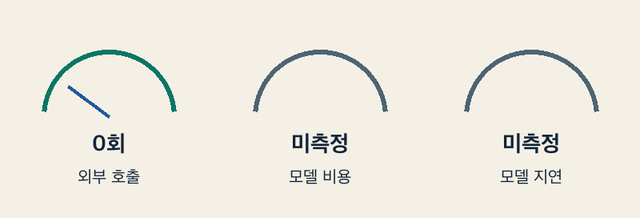

로컬 규칙에서 외부 모델 호출은 0회입니다. 모델 비용과 지연은 재지 않았으므로 계기판에 0을 채우지 않습니다.
<!-- /motion -->


### 셀 02 · 원 단위 수치를 비워 둔 까닭 읽기

후보의 비용 관측 필드만 꺼내 봅니다.

In [2]:
usage = {'external_model_calls': 0, 'model_cost': None, 'model_latency': None}
print(usage)

{'external_model_calls': 0, 'model_cost': None, 'model_latency': None}


외부 호출 수는 0이고 비용과 지연은 None입니다. 측정하지 않은 값을 0원이나 0초로 덮어쓰면 실제 모델과 비교할 수 없습니다. 팀이 실제 연동을 사용한다면 요청별 입력량·출력량·적용 요금·측정 구간을 남겨 계산하세요.

## 돌아보기

다음 단계에 넘길 한 줄은 ‘검색 고정, Q03에서 생성 인용만 수정, 나머지 세 질문으로 회귀 확인’입니다. 팀에서 실패가 가장 많은 원인이 다르면 근거 행과 함께 우선순위를 바꾸세요.